# 02. Exploratory Data Analysis (EDA)
**Project 26:** Card Fraud Triage  
**Team ID:** T047 (Section A)

---
> **Leakage rule:** every analysis here that looks at fraud labels uses the **training period only** (the first 60% of time, the same cut as notebook 01). Validation and test labels are never looked at, so the feature list we pick here is fair to use in modelling.

### What we are doing in this notebook:
1. Convert `Time` to hour of the day (0 to 24) to see when fraud happens.
2. Look at `Amount` and see why `log(1 + Amount)` makes it much better for modeling.
3. Compare normal vs fraud on the 28 mystery features ($V_1$ to $V_{28}$).
4. Find the best features that separate fraud from normal, and save them to `configs/gmm_features.json`.
5. Check correlations between features.
6. Check why one bell curve is not enough (we need a mixture of bell curves!).

### Step 1: Import libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Output folder for saving charts
fig_dir = '../results/figures'
if not os.path.exists(fig_dir):
    fig_dir = 'results/figures'
os.makedirs(fig_dir, exist_ok=True)

print("Libraries imported!")

Libraries imported!


### Step 2: Load the dataset and keep only the training period

In [2]:
file_path = '../data/raw/creditcard.csv'
if not os.path.exists(file_path):
    file_path = 'data/raw/creditcard.csv'

# Same cleaning and chronological cut as notebook 01
full_df = pd.read_csv(file_path).drop_duplicates().sort_values(by='Time').reset_index(drop=True)
train_end = int(0.60 * len(full_df))

# Training period only (fraud kept here for analysis; it is removed before model training)
df = full_df.iloc[:train_end].copy()

normal_df = df[df['Class'] == 0]
fraud_df = df[df['Class'] == 1]

print("Training-period rows:", len(df))
print("Normal transactions:", len(normal_df))
print("Fraud transactions: ", len(fraud_df))

Training-period rows: 170235
Normal transactions: 169893
Fraud transactions:  342


### Step 3: When does fraud happen? (Hour of Day)
Formula:
`Hour = (Time / 3600) % 24`
- Dividing by 3600 turns seconds into hours.
- `% 24` finds the hour on a 24-hour wall clock.

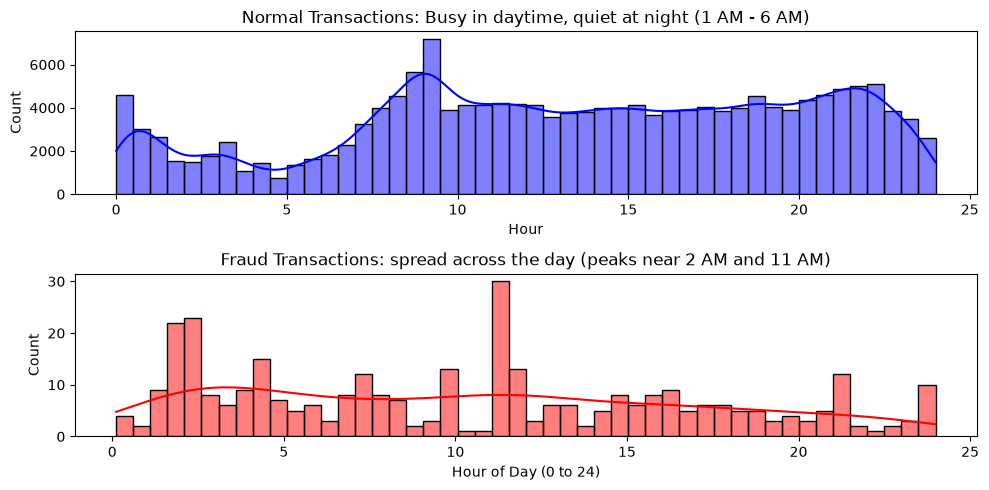

In [3]:
df['Hour'] = (df['Time'] / 3600) % 24

plt.figure(figsize=(10, 5))

# Normal transactions
plt.subplot(2, 1, 1)
sns.histplot(df[df['Class'] == 0]['Hour'], bins=48, color='blue', kde=True)
plt.title("Normal Transactions: Busy in daytime, quiet at night (1 AM - 6 AM)")
plt.ylabel("Count")

# Fraud transactions
plt.subplot(2, 1, 2)
sns.histplot(df[df['Class'] == 1]['Hour'], bins=48, color='red', kde=True)
plt.title("Fraud Transactions: spread across the day (peaks near 2 AM and 11 AM)")
plt.xlabel("Hour of Day (0 to 24)")
plt.ylabel("Count")

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'fig1_time_diurnal_distribution.png'))
plt.show()

### Step 4: Transaction Amount & Log Transform
Most transactions are small (€20), but some are €25,000.
Taking `log(1 + Amount)` shrinks the huge numbers down so they look like a normal bell curve.

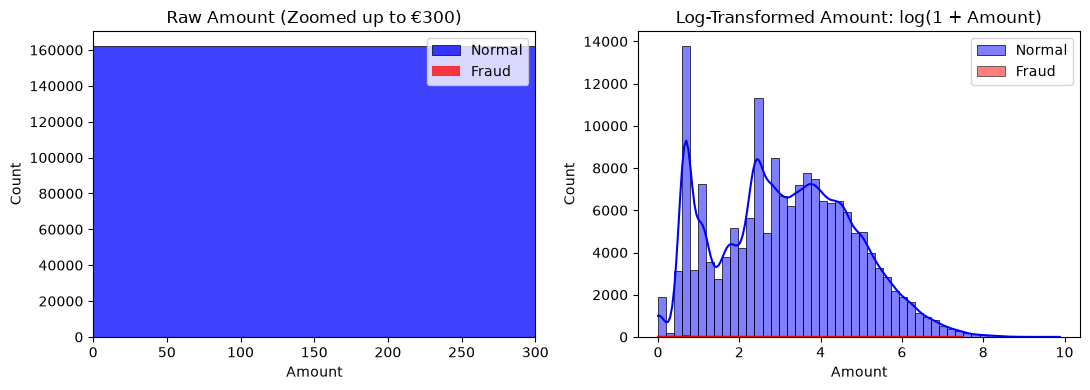

Raw Amount skewness: 15.771382088791718
Log Amount skewness: 0.16020962226520222


In [4]:
plt.figure(figsize=(11, 4))

# Raw amount up to €300
plt.subplot(1, 2, 1)
sns.histplot(normal_df['Amount'], bins=50, color='blue', label='Normal')
sns.histplot(fraud_df['Amount'], bins=50, color='red', label='Fraud')
plt.xlim(0, 300)
plt.title("Raw Amount (Zoomed up to €300)")
plt.legend()

# Log of amount
plt.subplot(1, 2, 2)
sns.histplot(np.log1p(normal_df['Amount']), bins=50, color='blue', label='Normal', kde=True)
sns.histplot(np.log1p(fraud_df['Amount']), bins=50, color='red', label='Fraud', kde=True)
plt.title("Log-Transformed Amount: log(1 + Amount)")
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'fig2_amount_distribution_log.png'))
plt.show()

print("Raw Amount skewness:", stats.skew(df['Amount']))
print("Log Amount skewness:", stats.skew(np.log1p(df['Amount'])))

### Step 5: Find which features separate fraud from normal
We compare normal vs fraud for all features from $V_1$ to $V_{28}$ using a two-sample Kolmogorov–Smirnov (KS) test, **on the training period only**.
A higher score (closer to 1.0) means fraud and normal look very different in that feature!

In [5]:
import json

scores = []
for i in range(1, 29):
    col = f'V{i}'
    stat, _ = stats.ks_2samp(normal_df[col], fraud_df[col])
    scores.append({'feature': col, 'separation_score': stat})

scores_df = pd.DataFrame(scores).sort_values(by='separation_score', ascending=False).reset_index(drop=True)
print("Top 12 features with biggest difference between normal and fraud (training period):")
print(scores_df.head(12))

# Save the top 11 V-features + Amount for the GMM notebooks
selected_features = scores_df.head(11)['feature'].tolist() + ['Amount']
config_dir = '../configs'
if not os.path.exists(config_dir):
    config_dir = 'configs'
os.makedirs(config_dir, exist_ok=True)
with open(os.path.join(config_dir, 'gmm_features.json'), 'w') as f:
    json.dump({'selected_features': selected_features,
               'selection': 'Top 11 V-features by KS statistic on the training period (first 60% of time) + Amount'}, f, indent=4)
print("\nSaved selected features:", selected_features)

Top 12 features with biggest difference between normal and fraud (training period):
   feature  separation_score
0      V14          0.847212
1      V10          0.823983
2      V12          0.792121
3      V11          0.776422
4      V17          0.775977
5       V4          0.773860
6       V3          0.735379
7      V16          0.731877
8       V7          0.711836
9       V2          0.657902
10      V9          0.580035
11     V18          0.567611

Saved selected features: ['V14', 'V10', 'V12', 'V11', 'V17', 'V4', 'V3', 'V16', 'V7', 'V2', 'V9', 'Amount']


### Step 6: Plot the top 6 features (Blue = Normal, Red = Fraud)

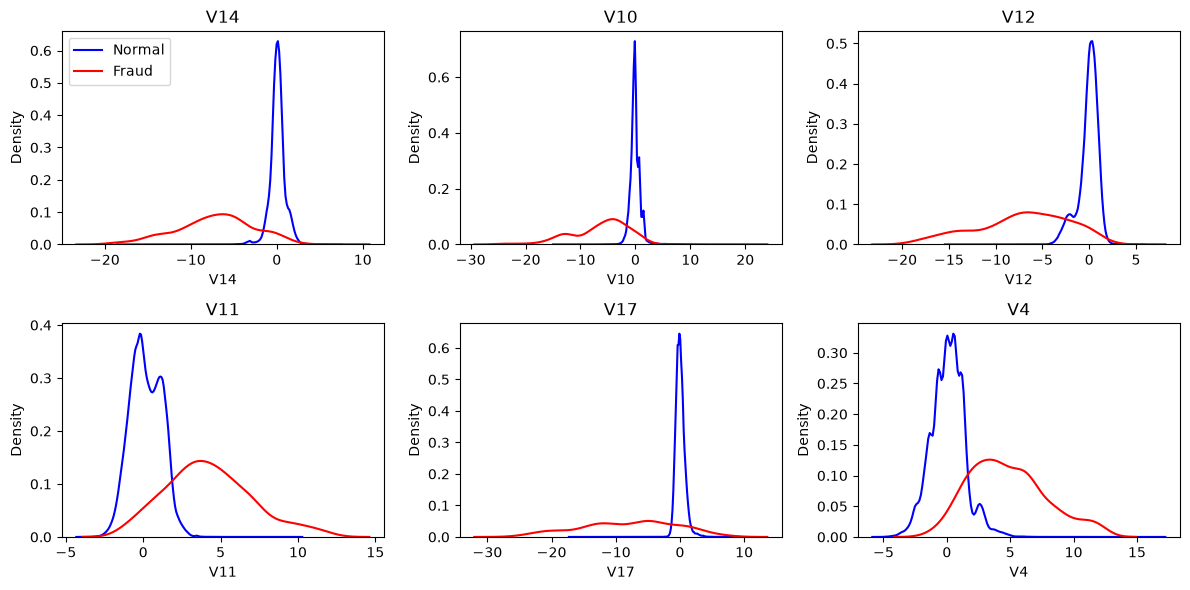

In [6]:
top6 = scores_df.head(6)['feature'].tolist()

plt.figure(figsize=(12, 6))
for i, col in enumerate(top6):
    plt.subplot(2, 3, i + 1)
    sns.kdeplot(normal_df[col], color='blue', label='Normal')
    sns.kdeplot(fraud_df[col], color='red', label='Fraud')
    plt.title(f"{col}")
    if i == 0:
        plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'fig3_top_divergent_features_kde.png'))
plt.show()

### Step 7: Correlation Heatmap

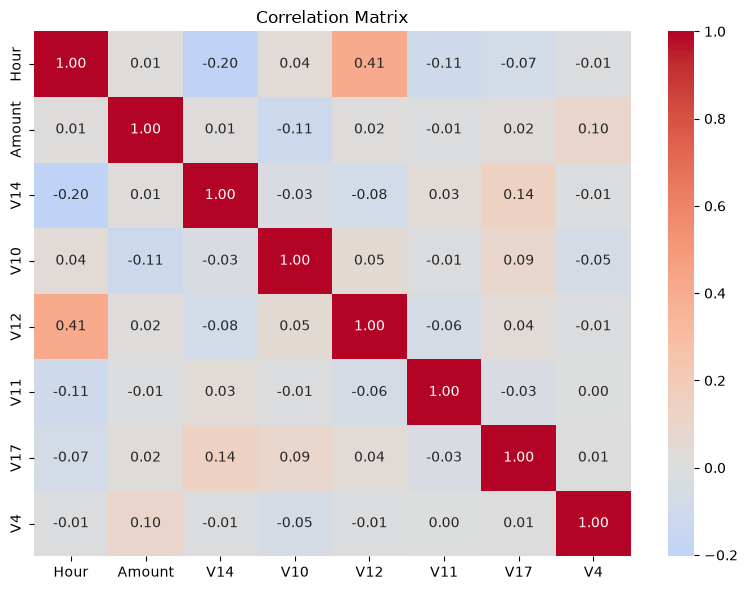

In [7]:
cols_to_check = ['Hour', 'Amount'] + top6
corr = df[cols_to_check].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'fig4_feature_correlation_matrix.png'))
plt.show()

### Step 8: Why do we need a mixture of bell curves (GMM)?
Can one single bell curve describe all honest cardholders?
We run D'Agostino–Pearson normality tests on normal transactions (Amount is tested after the log transform we actually use):

In [8]:
tests = {
    'log(1+Amount)': np.log1p(normal_df['Amount']),
    'V1': normal_df['V1'],
    'V4': normal_df['V4'],
    'V14': normal_df['V14'],
}
for name, values in tests.items():
    stat, p = stats.normaltest(values)
    verdict = "rejected" if p < 0.001 else "not rejected"
    p_text = f"{p:.3g}" if p > 0 else "< 1e-300 (underflows to 0)"
    print(f"{name:<14} statistic = {stat:>12,.1f}   p-value = {p_text}   -> single Gaussian {verdict}")

print("\nIf a single Gaussian is rejected, normal behaviour is better described by a mixture of Gaussians (GMM).")

log(1+Amount)  statistic =      7,495.5   p-value = < 1e-300 (underflows to 0)   -> single Gaussian rejected
V1             statistic =    128,016.9   p-value = < 1e-300 (underflows to 0)   -> single Gaussian rejected
V4             statistic =      9,396.4   p-value = < 1e-300 (underflows to 0)   -> single Gaussian rejected
V14            statistic =     44,187.6   p-value = < 1e-300 (underflows to 0)   -> single Gaussian rejected

If a single Gaussian is rejected, normal behaviour is better described by a mixture of Gaussians (GMM).
